<a href="https://colab.research.google.com/github/nakitava/image_processing/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22%D0%A8%D0%B5%D0%B2%D0%B5%D0%BB%D0%B5%D0%B2_%D0%94%D0%BC%D0%B8%D1%82%D1%80%D0%B8%D0%B9_%D0%9B%D0%B5%D0%BE%D0%BD%D0%B8%D0%B4%D0%BE%D0%B2%D0%B8%D1%87%09_%D0%94%D0%9F%D0%9E_%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%965_%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%D1%81_%D1%80%D0%B0%D1%81%D1%82%D1%80%D0%BE%D0%B2%D1%8B%D0%BC%D0%B8_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D0%BC%D0%B8_%D0%B2_Rasterio_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №5. Работа с растровыми данными в Rasterio**

In [1]:
!wget -q -nc https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
!wget -q -nc https://github.com/opengeos/datasets/releases/download/raster/cog.tif

In [2]:
import rasterio, numpy as np, matplotlib.pyplot as plt
from rasterio.windows import Window, transform as wtransform
from rasterio.warp import calculate_default_transform, reproject, Resampling

---

**Данные для обработки:**

- Одноканальное изображение (ЦМР): https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
- Мультиспектральное изображение (Landsat): https://github.com/opengeos/datasets/releases/download/raster/cog.tif

### **Задание 1. Чтение и исследование растровых данных**



1. Откройте одноканальное изображение ЦМР с использованием `rasterio`.


In [3]:
dem = rasterio.open('dem_90m.tif')
print(dem)

<open DatasetReader name='dem_90m.tif' mode='r'>


2. Извлеките и выведите метаданные растра, включая СК, разрешение, границы, количество каналов и типы данных.


In [4]:
print('СК:', dem.crs)
print('разрешение:', dem.res)
print('границы:', dem.bounds)
print('каналов:', dem.count)
print('типы:', dem.dtypes)

СК: EPSG:3857
разрешение: (90.0, 89.99579177642138)
границы: BoundingBox(left=-13442488.3428, bottom=4388214.6777, right=-13058278.3428, top=4668371.5775)
каналов: 1
типы: ('int16',)


3. Отобразите ширину и высоту растра, а также типы данных пикселей, чтобы понять размеры сетки и структуру данных.

In [5]:
print('ширина:', dem.width)
print('высота:', dem.height)
print('тип пикселей:', dem.dtypes[0])
dem_arr = dem.read(1)
print('массив:', dem_arr.shape)
print('диапазон:', dem_arr.min(), '~', dem_arr.max())

ширина: 4269
высота: 3113
тип пикселей: int16
массив: (3113, 4269)
диапазон: 15 ~ 4338


---



### **Задание 2. Визуализация и манипулирование растровыми каналами**



1. Визуализируйте одноканальное изображение ЦМР с использованием пользовательской цветовой карты (например, cmap='terrain').


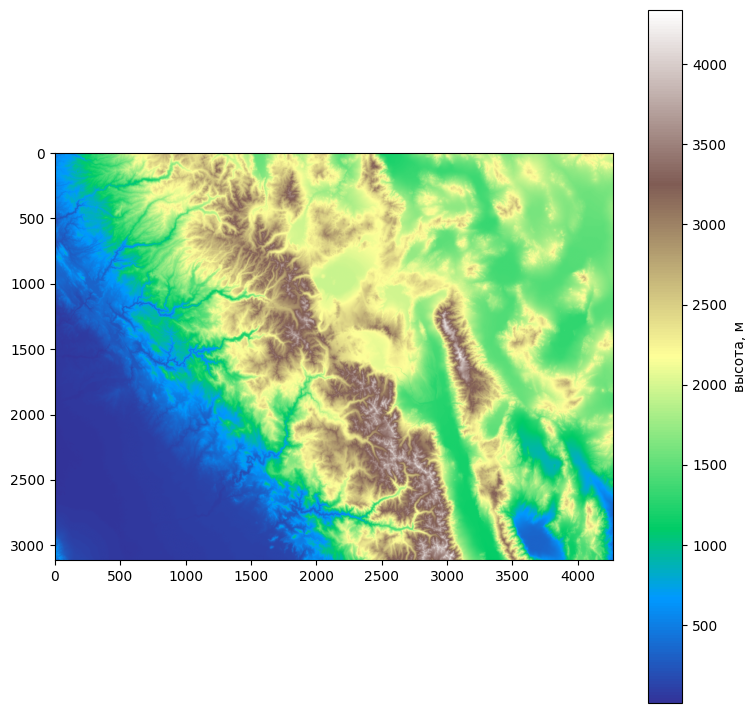

In [6]:
plt.figure(figsize=(9, 9))
plt.imshow(dem_arr, cmap='terrain')
plt.colorbar(label='высота, м')
plt.show()

2. Откройте мультиспектральное изображение и визуализируйте первый канал с использованием подходящей цветовой карты.


каналов: 4 | тип: float64 | CRS: EPSG:4326


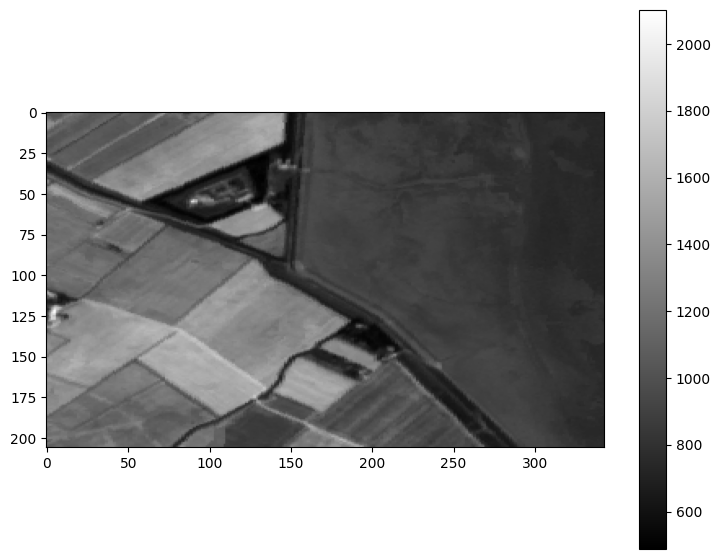

In [7]:
ms = rasterio.open('cog.tif')
print('каналов:', ms.count, '| тип:', ms.dtypes[0], '| CRS:', ms.crs)
plt.figure(figsize=(9, 7))
plt.imshow(ms.read(1), cmap='gray')
plt.colorbar()
plt.show()

3. Объедините несколько каналов из мультиспектрального изображения (например, Красный, Зеленый и Синий) и совместите их в один массив для создания RGB-композитного изображения.

>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

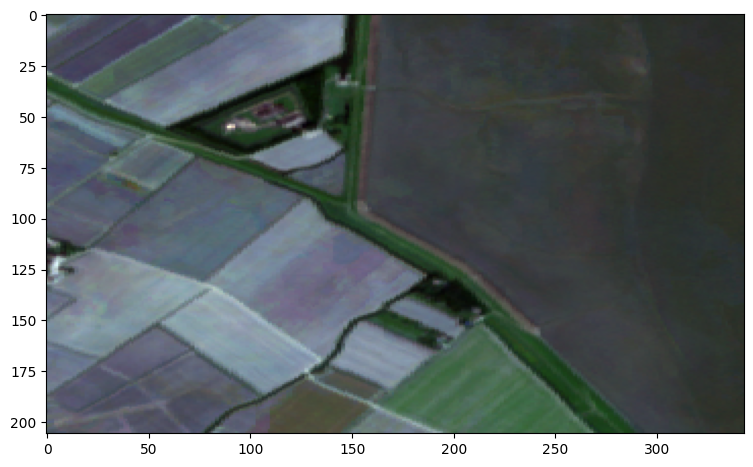

In [8]:
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm

rgb = np.dstack((normalize(ms.read(3)), normalize(ms.read(2)), normalize(ms.read(1))))
plt.figure(figsize=(9, 9))
plt.imshow(rgb)
plt.show()

---



### **Задание 3. Обрезка растра с использованием индексации массива**



1. Откройте мультиспектральное изображение и обрежьте его с использованием спискового среза (указав диапазоны строк и столбцов).


In [9]:
rows, cols = slice(100, 500), slice(100, 500)
crop = ms.read(window=(rows, cols))
print(crop.shape)

(4, 106, 243)


2. Визуализируйте обрезанную часть изображения с использованием matplotlib, чтобы убедиться в корректном результате.


>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

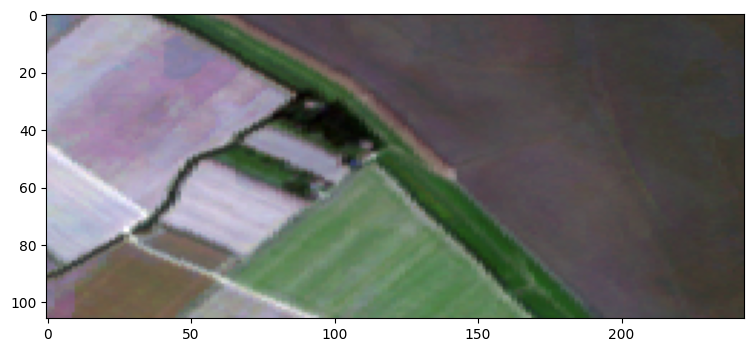

In [10]:
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm

crop_rgb = np.dstack((normalize(crop[2]), normalize(crop[1]), normalize(crop[0])))
plt.figure(figsize=(9, 9))
plt.imshow(crop_rgb)
plt.show()

3. Сохраните обрезанное подмножество растра в новый файл с именем `clipped_multispectral.tif`.

In [11]:
prof = ms.profile.copy()
prof.update(height=crop.shape[1], width=crop.shape[2],
    transform=wtransform(Window(cols.start, rows.start,
        cols.stop - cols.start, rows.stop - rows.start), ms.transform))
with rasterio.open('clipped_multispectral.tif', 'w', **prof) as dst:
    dst.write(crop)

---



### **Задание 4. Вычисление NDWI (калькуляция каналов)**



1. Откройте мультиспектральное изображение и извлеките каналы Green (Зеленый) и Ближний инфракрасный (NIR).


In [12]:
green = ms.read(2).astype('float32')
nir = ms.read(4).astype('float32')

2. Вычислите Нормализованный разностный водный индекс ([NDWI](https://en.wikipedia.org/wiki/Normalized_difference_water_index)) по формуле:

    NDWI = (Green - NIR) / (Green + NIR)

In [13]:
ndwi = (green - nir) / (green + nir)
print('NDWI:', ndwi.min(), '~', ndwi.max())

NDWI: -0.6217617 ~ 0.47722894


3. Визуализируйте результат NDWI с использованием цветовой карты, подходящей для воды (например, cmap='Blues'), чтобы выделить водные объекты.


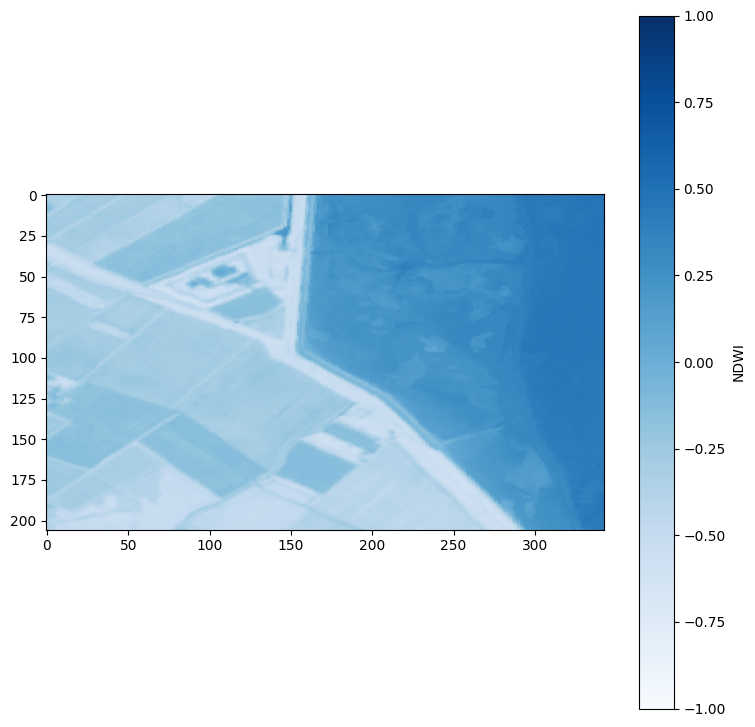

In [14]:
plt.figure(figsize=(9, 9))
plt.imshow(ndwi, cmap='Blues', vmin=-1, vmax=1)
plt.colorbar(label='NDWI')
plt.show()



4. Сохраните полученное изображение NDWI как новый растровый файл с именем ndwi.tif.

In [15]:
ndwi_prof = ms.profile.copy()
ndwi_prof.update(count=1, dtype='float32', nodata=np.nan)
with rasterio.open('ndwi.tif', 'w', **ndwi_prof) as dst:
    dst.write(ndwi, 1)

---



### **Задание 5. Перепроецирование растровых данных**



1. Перепроецируйте одноканальный растр ЦМР из его исходной СК в EPSG:4326 (WGS 84) с использованием функции `rasterio.warp.reproject`.


In [16]:
dst_crs = 'EPSG:4326'
with rasterio.open('dem_90m.tif') as src:
    tr, w, h = calculate_default_transform(src.crs, dst_crs, src.width, src.height, *src.bounds)
    kw = src.meta.copy()
    kw.update(crs=dst_crs, transform=tr, width=w, height=h)
    with rasterio.open('reprojected_dem.tif', 'w', **kw) as dst:
        for i in range(1, src.count + 1):
            reproject(source=rasterio.band(src, i), destination=rasterio.band(dst, i),
                src_transform=src.transform, src_crs=src.crs,
                dst_transform=tr, dst_crs=dst_crs, resampling=Resampling.bilinear)

2. Сохраните перепроецированный растр в новый файл GeoTIFF с именем `reprojected_dem.tif`.


In [18]:
rep = rasterio.open('reprojected_dem.tif')
print('исходная СК:', dem.crs, '| новая СК:', rep.crs)
print('было:', dem.width, dem.height, '| стало:', rep.width, rep.height)

исходная СК: EPSG:3857 | новая СК: EPSG:4326
было: 4269 3113 | стало: 4575 2642


3. Визуализируйте как исходный, так и перепроецированный наборы данных ЦМР, чтобы сравнить, как перепроецирование влияет на пространственное покрытие и разрешение.

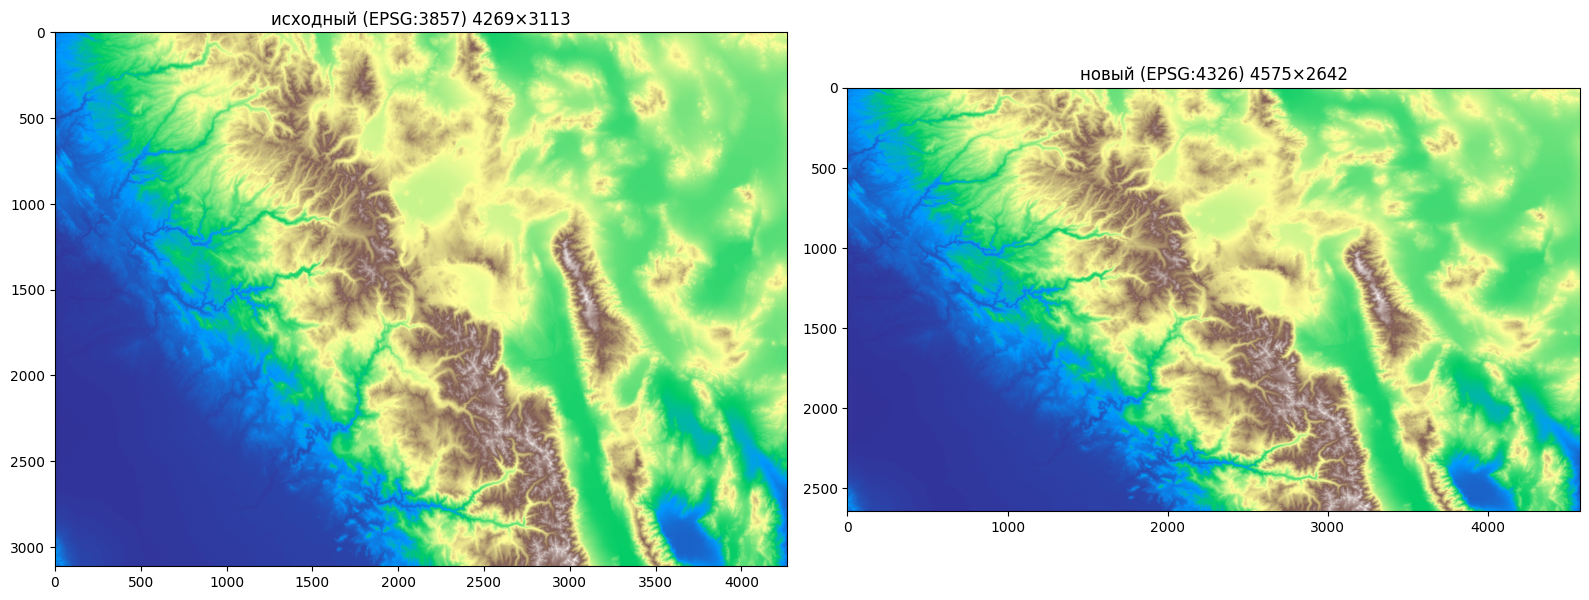

In [19]:
rep_arr = rep.read(1)
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].imshow(dem_arr, cmap='terrain')
ax[0].set_title(f'исходный ({dem.crs}) {dem.width}×{dem.height}')
ax[1].imshow(rep_arr, cmap='terrain')
ax[1].set_title(f'новый ({rep.crs}) {rep.width}×{rep.height}')
plt.tight_layout()
plt.show()

---